# Нейронні мережі. Навчання нейронної мережі (TensorFlow/Keras, MNIST)


## 2. Підключення бібліотек

In [11]:
# Підключаємо бібліотеки
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
print('Версія TensorFlow:', tf.__version__)
print('Бібліотеки підключено успішно!')

Версія TensorFlow: 2.21.0
Бібліотеки підключено успішно!


## 3. Завантаження набору даних MNIST

In [12]:
# Завантажуємо набір даних MNIST
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print('Навчальних зображень:', x_train.shape[0])
print('Тестових зображень: ', x_test.shape[0])
print('Розмір зображення: ', x_train.shape[1], 'x', x_train.shape[2], 'пікселів')

Навчальних зображень: 60000
Тестових зображень:  10000
Розмір зображення:  28 x 28 пікселів


## 4. Перегляд прикладів

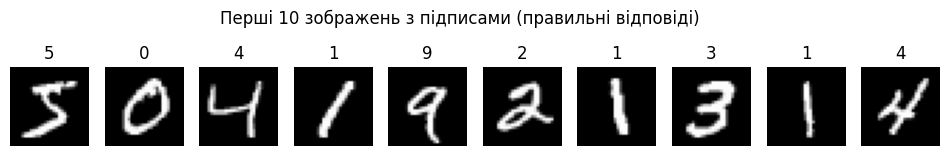

In [13]:
# Показуємо перші 10 прикладів
plt.figure(figsize=(12, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(str(y_train[i]))
    plt.axis('off')
plt.suptitle('Перші 10 зображень з підписами (правильні відповіді)')
plt.show()

## 5. Нормалізація даних

In [14]:
# Нормалізуємо пікселі: з діапазону [0, 255] до [0, 1]
x_train = x_train / 255.0
x_test = x_test / 255.0
print('Готово! Діапазон значень тепер від', x_train.min(), 'до', x_train.max())

Готово! Діапазон значень тепер від 0.0 до 1.0


## 6. Побудова нейронної мережі

In [15]:
# Будуємо модель нейронної мережі
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    # Шар 1: розгортаємо зображення 28x28 у вектор з 784 чисел
    keras.layers.Flatten(),
    # Шар 2: прихований шар - 128 нейронів, функція активації ReLU
    keras.layers.Dense(128, activation='relu'),
    # Шар 3: вихідний шар - 10 нейронів (по одному на кожну цифру 0-9)
    keras.layers.Dense(10, activation='softmax')
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Навчання мережі

In [16]:
# Налаштовуємо процес навчання
model.compile(
    optimizer='adam',                        # Алгоритм оновлення ваг
    loss='sparse_categorical_crossentropy',  # Функція помилки
    metrics=['accuracy']                     # Відстежуємо точність
)
print('Модель готова до навчання!')

Модель готова до навчання!


In [17]:
# Навчаємо модель
history = model.fit(
    x_train, y_train,
    epochs=5,              # Кількість проходів по всіх даних
    batch_size=32,         # Скільки прикладів за один крок
    validation_split=0.1   # 10% навчальних даних - для перевірки
)
print('Навчання завершено!')

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9216 - loss: 0.2747 - val_accuracy: 0.9653 - val_loss: 0.1295
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9647 - loss: 0.1182 - val_accuracy: 0.9717 - val_loss: 0.0997
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9754 - loss: 0.0810 - val_accuracy: 0.9748 - val_loss: 0.0914
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9814 - loss: 0.0610 - val_accuracy: 0.9777 - val_loss: 0.0751
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9855 - loss: 0.0475 - val_accuracy: 0.9785 - val_loss: 0.0718
Навчання завершено!


## 8. Оцінка точності на тестових даних

In [18]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f'Точність на тестових даних: {test_accuracy * 100:.2f}%')
print(f'Помилка (loss): {test_loss:.4f}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9747 - loss: 0.0789
Точність на тестових даних: 97.47%
Помилка (loss): 0.0789


## 9. Графік навчання

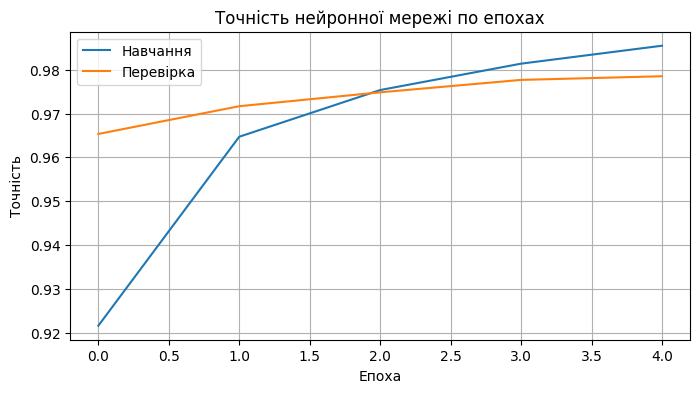

In [19]:
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Навчання')
plt.plot(history.history['val_accuracy'], label='Перевірка')
plt.title('Точність нейронної мережі по епохах')
plt.xlabel('Епоха')
plt.ylabel('Точність')
plt.legend()
plt.grid(True)
plt.show()

## 10. Перевірка на конкретних прикладах

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step


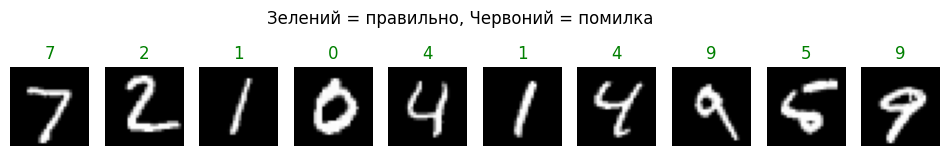

In [20]:
predictions = model.predict(x_test[:10])
plt.figure(figsize=(12, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    predicted = np.argmax(predictions[i])  # Клас з найбільшою ймовірністю
    color = 'green' if predicted == y_test[i] else 'red'
    plt.title(str(predicted), color=color)
    plt.axis('off')
plt.suptitle('Зелений = правильно, Червоний = помилка')
plt.show()

# Завдання для самостійного виконання
Зручна функція `run_experiment`, щоб порівнювати конфігурації. Результати збираються в таблицю наприкінці.

In [22]:
results = []

def run_experiment(name, hidden=(128,), epochs=5, n_train=60000, n_test=10000, verbose=0):
    # hidden - кортеж з кількістю нейронів у кожному прихованому шарі
    layers = [keras.Input(shape=(28, 28)), keras.layers.Flatten()]
    for units in hidden:
        layers.append(keras.layers.Dense(units, activation='relu'))
    layers.append(keras.layers.Dense(10, activation='softmax'))
    m = keras.Sequential(layers)
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(x_train[:n_train], y_train[:n_train], epochs=epochs,
              batch_size=32, validation_split=0.1, verbose=verbose)
    loss, acc = m.evaluate(x_test[:n_test], y_test[:n_test], verbose=0)
    results.append((name, hidden, epochs, n_train, n_test, round(acc*100, 2)))
    print(f'{name}: точність на тесті = {acc*100:.2f}%')
    return m, h

### Завдання 1. Змінити розмір вибірок і кількість епох

In [23]:
run_experiment('Базова (60000/10000, 5 епох)')
run_experiment('Менша вибірка (10000/2000, 5 епох)', n_train=10000, n_test=2000)
run_experiment('Менша вибірка (10000/2000, 2 епохи)', n_train=10000, n_test=2000, epochs=2)

Базова (60000/10000, 5 епох): точність на тесті = 97.40%
Менша вибірка (10000/2000, 5 епох): точність на тесті = 92.00%
Менша вибірка (10000/2000, 2 епохи): точність на тесті = 90.30%


(<Sequential name=sequential_4, built=True>,
 <keras.src.callbacks.history.History at 0x7d4dd76db2f0>)

### Завдання 2. 64 нейрони у прихованому шарі

In [25]:
run_experiment('64 нейрони', hidden=(64,))

64 нейрони: точність на тесті = 97.04%


(<Sequential name=sequential_6, built=True>,
 <keras.src.callbacks.history.History at 0x7d4dd80f3680>)

### Завдання 3. 10 епох

In [26]:
m10, h10 = run_experiment('128 нейронів, 10 епох', epochs=10)

128 нейронів, 10 епох: точність на тесті = 97.80%


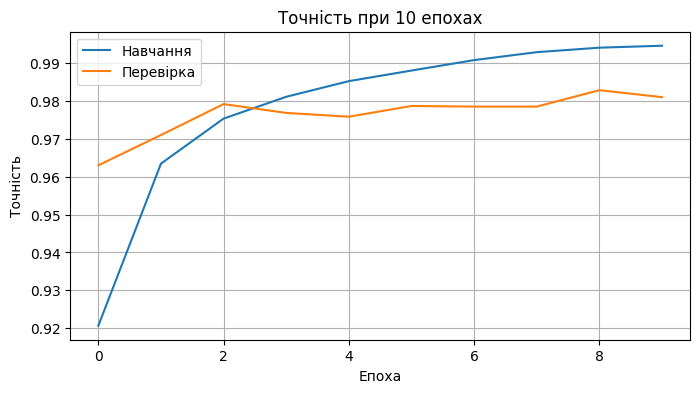

In [27]:
plt.figure(figsize=(8, 4))
plt.plot(h10.history['accuracy'], label='Навчання')
plt.plot(h10.history['val_accuracy'], label='Перевірка')
plt.title('Точність при 10 епохах')
plt.xlabel('Епоха'); plt.ylabel('Точність'); plt.legend(); plt.grid(True)
plt.show()

### Завдання 4. Додатковий прихований шар Dense(64)

In [28]:
m2, h2 = run_experiment('128 + 64 нейрони', hidden=(128, 64))

128 + 64 нейрони: точність на тесті = 97.17%


### Завдання 5. Приклад, де мережа помилилась

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
Кількість помилок на тесті: 253


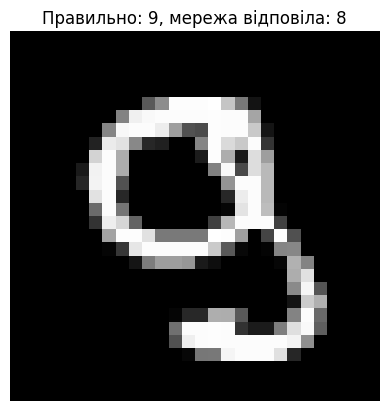

In [29]:
pred_all = np.argmax(model.predict(x_test), axis=1)
wrong = np.where(pred_all != y_test)[0]
print('Кількість помилок на тесті:', len(wrong))
i = wrong[0]
plt.imshow(x_test[i], cmap='gray')
plt.title(f'Правильно: {y_test[i]}, мережа відповіла: {pred_all[i]}')
plt.axis('off')
plt.show()

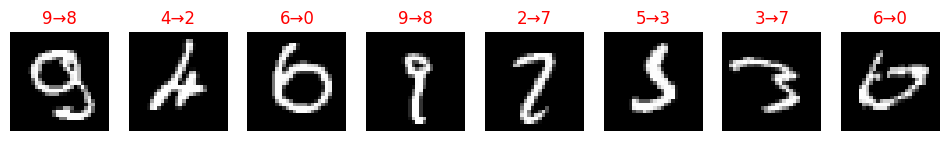

In [30]:
# Додатково: перші 8 помилок
plt.figure(figsize=(12, 2))
for k, idx in enumerate(wrong[:8]):
    plt.subplot(1, 8, k + 1)
    plt.imshow(x_test[idx], cmap='gray')
    plt.title(f'{y_test[idx]}→{pred_all[idx]}', color='red')
    plt.axis('off')
plt.show()

### Підсумкова таблиця результатів

In [31]:
import pandas as pd
df = pd.DataFrame(results, columns=['Експеримент', 'Приховані шари', 'Епохи', 'Навч. вибірка', 'Тест. вибірка', 'Точність, %'])
df

,Експеримент,Приховані шари,Епохи,Навч. вибірка,Тест. вибірка,"Точність, %"
0,"Базова (60000/10000, 5 епох)","(128,)",5,60000,10000,97.40
1,"Менша вибірка (10000/2000, 5 епох)","(128,)",5,10000,2000,92.00
2,"Менша вибірка (10000/2000, 2 епохи)","(128,)",2,10000,2000,90.30
3,64 нейрони,"(64,)",5,60000,10000,97.13
4,64 нейрони,"(64,)",5,60000,10000,97.04
5,"128 нейронів, 10 епох","(128,)",10,60000,10000,97.80
6,128 + 64 нейрони,"(128, 64)",5,60000,10000,97.17


## Висновки
У роботі побудовано та навчено повнозв'язну нейронну мережу (Flatten → Dense(128, ReLU) → Dense(10, softmax)) для розпізнавання рукописних цифр MNIST засобами TensorFlow/Keras у Google Colab. Базова модель після 5 епох досягла точності 97,40% на тестовій вибірці.

Розмір вибірки та кількість епох. Зменшення навчальної вибірки з 60 000 до 10 000 зображень знизило точність до 92,00%, а зменшення кількості епох до 2 знизило її ще до 90,30%. Чим менше даних і кількість проходів, тим гірше мережа підбирає ваги.
64 нейрони замість 128. Точність майже не змінилась: 97,13% і 97,04% у двох запусках проти 97,40%. Різниця близько 0,3 в. п. Між двома запусками з однаковими параметрами теж є відмінність (0,09 в. п.) через випадкову ініціалізацію ваг. Отже, для цієї задачі менша мережа майже не поступається більшій.
10 епох замість 5. Точність зросла до 97,80% (+0,4 в. п.). На графіку точність на навчальній вибірці продовжує рости й досягає близько 99,5%. Точність на перевірочній вибірці виходить на плато близько 98% уже після 2-3 епохи й далі майже не зростає. Зростаючий розрив між кривими свідчить про початок перенавчання: мережа дедалі краще запам'ятовує навчальні приклади, але узагальнює не краще.
Додатковий прихований шар Dense(64). Точність становить 97,17%, що не краще за базову модель (97,40%). Складніша архітектура не дала виграшу, бо простої мережі з одним прихованим шаром достатньо для MNIST.
Аналіз помилок. На тестовій вибірці мережа помилилась на 253 зображеннях з 10 000. Помилки трапляються на нечітких або незвично написаних цифрах, наприклад 9, яку мережа визначила як 8. Для таких зразків важко відрізнити цифри навіть людині.

Загалом найбільший вплив на якість мали обсяг навчальних даних і кількість епох, а зміна кількості нейронів і додавання шару суттєво на неї не вплинули.